# Same-section registration

When a second modality is imaged on the **same physical section** as your
spatial transcriptomics run (for example, a nuclear stain done after Xenium),
every nucleus sits in one Xenium cell. Registration is then a
*correspondence* problem: find the transform that puts each nucleus back in
its cell, then snap the confident pairs exactly onto their partners.

In this tutorial you will:

1. register a synthetic nuclei / cell pair with a **known** misalignment using
   `register_centroids` (method `multiround`), and check the result against the truth;
2. snap matched nuclei onto their cells with `refine_by_assignment`, and read
   its statuses and `neighbour_deviation`;
3. repeat both steps on a 1.5 mm × 1.5 mm crop of real data (Sample 2, section z5);
4. do the same from CSV files in one call, as the command line does.

**Runtime:** under a minute on a laptop CPU. **Requires:** SMINT only (no GPU,
no Cellpose, no STalign).

**Data.** The synthetic files are made by `python examples/make_tutorial_data.py`
and, like the Sample 2 crop, ship with the repository in `docs/tutorials/data/`.
Run this notebook from `docs/tutorials/` so the relative `data/` paths resolve.

**Download this notebook:** [02_same_section_registration.ipynb](02_same_section_registration.ipynb)

In [1]:
import logging
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Show SMINT's progress messages in the notebook
logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s",
                    stream=sys.stdout, force=True)
# The deprecated xenium_metabolomics module warns when STalign is absent; it is not used here
logging.getLogger("smint.alignment.xenium_metabolomics").setLevel(logging.ERROR)
# Per-call matching messages are very chatty; keep the round-by-round summary
logging.getLogger("smint.alignment.centroid_registration").addFilter(
    lambda record: not record.getMessage().startswith("Matched "))

from smint.alignment import alignment_quality, refine_by_assignment, register_centroids

CELL, NUC, ASSIGNED = "#2b6cb0", "#d53f8c", "#dd8a2e"


def status_legend(fig, pairs=True):
    """One legend for the three-panel figures: cells, and nuclei by status."""
    from matplotlib.lines import Line2D
    dot = lambda c, label: Line2D([], [], ls="", marker="o", ms=5, color=c, label=label)
    handles = [Line2D([], [], ls="", marker="o", ms=9, mfc="none", mec=CELL, label="Xenium cell"),
               dot(NUC, "nucleus (right panel: snapped)"), dot(ASSIGNED, "assigned"),
               dot("0.55", "filled (moved with neighbours)")]
    if pairs:
        handles.append(Line2D([], [], color="0.6", lw=0.8, label="line to true partner"))
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False,
               bbox_to_anchor=(0.5, -0.02))

## 1. Load the synthetic pair

`synthetic_cells.csv` plays the Xenium cells (the **target**, fixed) and
`synthetic_nuclei.csv` the post-stain nuclei (the **source**, moved). The
nuclei were displaced by about 17 µm — roughly one cell spacing, which is
what makes this hard — plus a 0.5° rotation, a 0.6% scale change and a smooth
warp of a few microns. As in real data, about 10% of cells have no nucleus and
there are extra nuclei with no cell.

In [2]:
cells = pd.read_csv("data/synthetic_cells.csv")
nuclei = pd.read_csv("data/synthetic_nuclei.csv")
truth = pd.read_csv("data/synthetic_same_section_truth.csv")   # only synthetic data has this

cells_xy = cells[["x_centroid", "y_centroid"]].to_numpy()
nuclei_xy = nuclei[["centroid_x", "centroid_y"]].to_numpy()
true_xy = truth[["x_true", "y_true"]].to_numpy()
true_cell = truth["true_cell"].to_numpy()          # -1: a nucleus with no cell

print(f"{len(cells_xy):,} cells, {len(nuclei_xy):,} nuclei "
      f"({(true_cell >= 0).sum():,} belong to a cell)")
print("before registration:", {k: round(v, 2) for k, v in alignment_quality(nuclei_xy, cells_xy).items()})

4,000 cells, 4,601 nuclei (3,601 belong to a cell)
before registration: {'median_nn': 12.86, 'mutual_within_5': 0.08, 'mutual_within_10': 0.29}


`alignment_quality` is a correspondence-free summary: `median_nn` is the median
distance from each nucleus to its nearest cell, and `mutual_within_5` the
fraction of nuclei whose nearest cell has them as its nearest nucleus too,
within 5 µm. Before registration few nuclei are mutual neighbours of their cell.

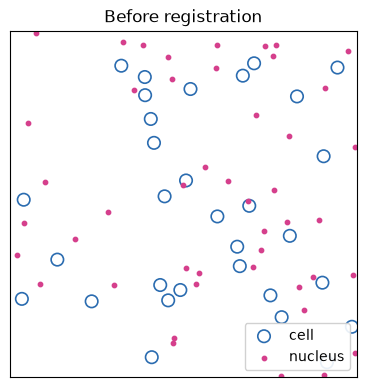

In [3]:
def panel(ax, cells, xy, title, window, colors=NUC, pairs=None):
    """Cells as open circles, nuclei as dots, in a 200 um window."""
    (x0, y0), w = window, 200
    inside = lambda p: (p[:, 0] > x0) & (p[:, 0] < x0 + w) & (p[:, 1] > y0) & (p[:, 1] < y0 + w)
    c = cells[inside(cells)]
    ax.scatter(c[:, 0], c[:, 1], s=80, facecolors="none", edgecolors=CELL, linewidths=1.2,
               label="cell")
    keep = inside(xy)
    if pairs is not None:
        for (a, b) in zip(xy[keep], pairs[keep]):
            ax.plot([a[0], b[0]], [a[1], b[1]], color="0.6", lw=0.6, zorder=0)
    ax.scatter(xy[keep, 0], xy[keep, 1], s=10,
               c=colors if isinstance(colors, str) else np.asarray(colors)[keep], label="nucleus")
    ax.set(xlim=(x0, x0 + w), ylim=(y0 + w, y0), aspect="equal", title=title)
    ax.set_xticks([]); ax.set_yticks([])

fig, ax = plt.subplots(figsize=(4.5, 4.5))
panel(ax, cells_xy, nuclei_xy, "Before registration", (900, 900))
ax.legend(loc="lower right", framealpha=0.9)
plt.show()

Most nuclei sit between two cells, and the nearest cell is often the wrong
one. Matching every nucleus to its nearest cell and fitting a transform to
those pairs — what the single-round methods do — would fit mostly wrong pairs.

## 2. Register with multiround

`register_centroids` with the default `method="multiround"` never commits to
individual pairs early. It cuts the section into blocks, lets every nucleus
vote for the displacements to several nearby cells, and takes the peak of the
votes in each block — the true offset is the one the whole block agrees on.
Round 1 fits an affine through the block peaks; round 2 votes again in smaller
blocks and adds a smooth thin-plate spline. A round is kept only if it
improves the alignment.

In [4]:
result = register_centroids(nuclei_xy, cells_xy)   # method="multiround", max_distance=100

INFO smint.alignment.centroid_registration: Initial TRE (held-out points, mutual NN <= 100.0): 12.3830


INFO smint.alignment.centroid_registration: RANSAC affine: 16/16 inliers (100.0%) at residual_threshold=6.0


INFO smint.alignment.centroid_registration: Round 1 (affine, 500-unit blocks): 16 blocks, 100% consistent, median NN 12.90 -> 3.60


INFO smint.alignment.centroid_registration: RANSAC affine: 55/64 inliers (85.9%) at residual_threshold=3.0


INFO smint.alignment.centroid_registration: Round 2 (tps, 250-unit blocks): 64 blocks, 86% consistent, median NN 3.60 -> 3.25


INFO smint.alignment.centroid_registration: TRE after multiround -- fit: 3.4414 | held-out validation: 4.5811


The log is the per-round summary that is also stored in `result["rounds"]`:

In [5]:
pd.DataFrame(result["rounds"]).round(2)

,stage,median_nn,max_distance,block_size,blocks,consistent_blocks,accepted
0,initial,12.90,NaN,NaN,NaN,NaN,NaN
1,affine,3.60,100.0,500.0,16.0,1.00,True
2,tps,3.25,25.0,250.0,64.0,0.86,True


How to read it:

- **blocks / consistent_blocks** — how many blocks had enough nuclei to vote,
  and the fraction whose peak agrees with the fitted model (RANSAC inliers).
  A low fraction means the blocks disagree: check the data before trusting the round.
- **median_nn** — the median nucleus-to-nearest-cell distance for the fitting
  nuclei after that round. It should fall.
- **accepted** — whether the round improved `median_nn` by at least
  `min_improvement` (1%). The first rejected round ends the schedule.

A quarter of the nuclei (`validation_fraction=0.25`) were held out before any
voting. `tre_validation` is measured on them only — it is the number to trust.

In [6]:
print(f"held-out TRE: {result['tre_initial'][0]:.1f} -> {result['tre_validation'][0]:.1f} um "
      f"(fit TRE {result['tre_fit'][0]:.1f} um)")
pd.DataFrame(result["validation"]).T.round(3)

held-out TRE: 12.4 -> 4.6 um (fit TRE 3.4 um)


,median_nn,mutual_within_5,mutual_within_10
before,12.751,0.079,0.326
after,3.262,0.728,0.832


Because this is synthetic data you can also score the transform against the
truth — the distance from each moved nucleus to where it really belongs:

In [7]:
smooth_xy = result["transform"](nuclei_xy)
has_cell = true_cell >= 0
before = np.linalg.norm(nuclei_xy - true_xy, axis=1)[has_cell]
after = np.linalg.norm(smooth_xy - true_xy, axis=1)[has_cell]
print(f"true error, median: {np.median(before):.1f} um before -> {np.median(after):.2f} um after")
print(f"true error, 95th percentile after: {np.percentile(after, 95):.2f} um")

true error, median: 18.0 um before -> 1.20 um after
true error, 95th percentile after: 2.89 um


The transform recovers the misalignment to about a micron. The held-out TRE is
larger than that because it measures distance to the nearest *cell centroid*,
and nuclei sit a few microns off-centre in their cells.

## 3. Snap nuclei onto their cells

A smooth transform cannot put every nucleus exactly on its cell.
`refine_by_assignment` does that in a second step:

1. pair moved nuclei and cells as mutual nearest neighbours within `snap_radius` (10 µm);
2. keep a pair only if its offset agrees with the median offset of the pairs
   around it (within `consistency_tol`, default 0.4 × the cell spacing) — a
   nucleus paired with the wrong cell disagrees with its neighbourhood;
3. move kept nuclei exactly onto their cell (**snapped**); move the rest by the
   median offset of their snapped neighbours (**filled**) and try pairing again,
   up to `passes` times;
4. pair leftover filled nuclei with still-free cells by a one-to-one
   minimum-distance assignment (**assigned**) — these skipped the
   neighbourhood check, so they are less certain.

In [8]:
refined = refine_by_assignment(nuclei_xy, cells_xy, transform=result["transform"])
status = refined["status"]
print(pd.Series(status).value_counts().to_string())
print(f"snapped per pass: {refined['snapped_per_pass']}")
print(f"cells that received a nucleus: {refined['fraction_targets_matched']:.1%}")

INFO smint.alignment.centroid_registration: Refinement: 3585 snapped and 64 assigned (91.2% of targets placed), 952 filled from neighbours; median neighbourhood deviation snapped 2.5 / assigned 8.1; held-out field check: median 2.44, 95% within 5


WARNING smint.alignment.centroid_registration: Assigned pairs deviate from their neighbourhood by a median 8.1 (snapped: 2.5): many are probably nuclei without a target placed on a neighbour's. Filter on neighbour_deviation, or use assign_remaining=False.


snapped     3585
filled       952
assigned      64
snapped per pass: [3567, 3583, 3585]
cells that received a nucleus: 91.2%


The synthetic truth says which cell each nucleus belongs to, so you can check
every placement:

In [9]:
partner = refined["target_idx"]
rows = []
for s in ("snapped", "assigned", "filled"):
    k = status == s
    rows.append({
        "status": s, "nuclei": int(k.sum()),
        "on the right cell": f"{np.mean(partner[k] == true_cell[k]):.1%}" if s != "filled" else "-",
        "nuclei with no cell": f"{np.mean(true_cell[k] < 0):.1%}",
        "median neighbour_deviation (um)": round(float(np.nanmedian(refined['neighbour_deviation'][k])), 1)
                                          if s != "filled" else "-",
    })
pd.DataFrame(rows).set_index("status")

,nuclei,on the right cell,nuclei with no cell,median neighbour_deviation (um)
status,,,,
snapped,3585,98.9%,1.1%,2.5
assigned,64,45.3%,53.1%,8.1
filled,952,-,97.4%,-


Snapped nuclei are almost all on the right cell. Assigned ones are much less
reliable: many are nuclei that have no cell of their own, placed on a
neighbour's. `neighbour_deviation` tells them apart without any truth — it is
the distance between a pair's offset and its snapped neighbourhood's median
offset: about the nucleus-in-cell scatter for a right pair, about a cell
spacing for a wrong one. SMINT logs a warning when assigned pairs deviate much
more than snapped ones, as above; filter on `neighbour_deviation` or pass
`assign_remaining=False` if you need only confident pairs.

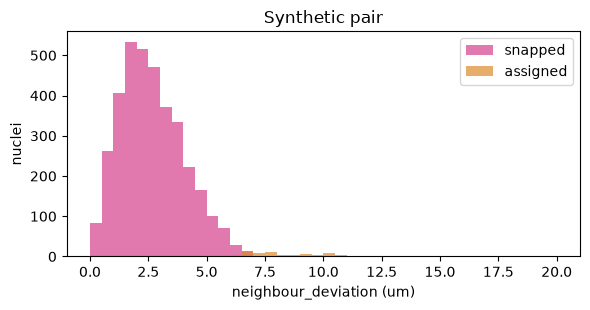

In [10]:
fig, ax = plt.subplots(figsize=(6, 3.2))
bins = np.linspace(0, 20, 41)
for s, c in (("snapped", NUC), ("assigned", ASSIGNED)):
    ax.hist(refined["neighbour_deviation"][status == s], bins=bins, color=c, alpha=0.7, label=s)
ax.set(xlabel="neighbour_deviation (um)", ylabel="nuclei", title="Synthetic pair")
ax.legend(); plt.tight_layout(); plt.show()

Before, after the smooth transform, and after snapping, in the same window
(grey lines join each nucleus to the cell it truly belongs to):

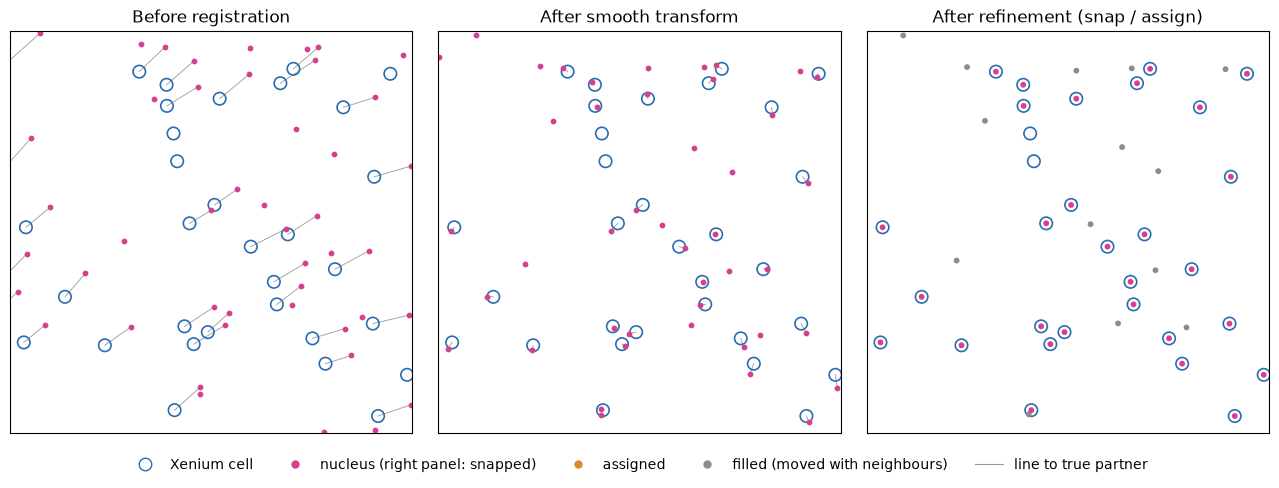

In [11]:
true_partner = np.where(has_cell[:, None], cells_xy[np.maximum(true_cell, 0)], np.nan)
colors = np.where(status == "snapped", NUC, np.where(status == "assigned", ASSIGNED, "0.55"))
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
panel(axes[0], cells_xy, nuclei_xy, "Before registration", (900, 900), pairs=true_partner)
panel(axes[1], cells_xy, smooth_xy, "After smooth transform", (900, 900), pairs=true_partner)
panel(axes[2], cells_xy, refined["refined_xy"], "After refinement (snap / assign)", (900, 900), colors=colors)
plt.tight_layout(rect=(0, 0.06, 1, 1)); status_legend(fig); plt.show()

## 4. Real data: Sample 2, section z5

The same two calls on a 1.5 mm × 1.5 mm crop of real data: nuclei segmented
from a stain done after the Xenium run, and the Xenium cells of that section.
Coordinates are in microns, re-origined to the crop corner. There is no truth
here, so the held-out numbers and the plots are the checks.

In [12]:
cells = pd.read_csv("data/sample2_xenium_z5_crop.csv")
nuclei = pd.read_csv("data/sample2_nuclei_z5_crop.csv")
cells_xy = cells[["x_centroid", "y_centroid"]].to_numpy()
nuclei_xy = nuclei[["centroid_x", "centroid_y"]].to_numpy()
print(f"{len(cells_xy):,} Xenium cells, {len(nuclei_xy):,} nuclei")

result = register_centroids(nuclei_xy, cells_xy)
pd.DataFrame(result["rounds"]).round(2)

2,476 Xenium cells, 2,500 nuclei
INFO smint.alignment.centroid_registration: Initial TRE (held-out points, mutual NN <= 100.0): 11.3629


INFO smint.alignment.centroid_registration: RANSAC affine: 9/9 inliers (100.0%) at residual_threshold=6.0


INFO smint.alignment.centroid_registration: Round 1 (affine, 500-unit blocks): 9 blocks, 100% consistent, median NN 11.52 -> 4.86


INFO smint.alignment.centroid_registration: RANSAC affine: 28/36 inliers (77.8%) at residual_threshold=3.0


INFO smint.alignment.centroid_registration: Round 2 (tps, 250-unit blocks): 36 blocks, 78% consistent, median NN 4.86 -> 4.97 -- not an improvement, stopping


INFO smint.alignment.centroid_registration: TRE after multiround -- fit: 4.6646 | held-out validation: 5.1646


,stage,median_nn,max_distance,block_size,blocks,consistent_blocks,accepted
0,initial,11.52,NaN,NaN,NaN,NaN,NaN
1,affine,4.86,100.0,500.0,9.0,1.00,True
2,tps,4.97,25.0,250.0,36.0,0.78,False


The affine round did the work here; the finer spline round did not improve the
fitting nuclei by 1%, so it was rejected and the affine kept. That is the same
pattern as on the whole section (see [Worked examples](../../examples/#3-same-section-registration-nuclei-onto-xenium-cells)).

In [13]:
print(f"held-out TRE: {result['tre_initial'][0]:.1f} -> {result['tre_validation'][0]:.1f} um")
print(pd.DataFrame(result["validation"]).T.round(3).to_string())

refined = refine_by_assignment(nuclei_xy, cells_xy, transform=result["transform"])
print(pd.Series(refined["status"]).value_counts().to_string())
print(f"cells that received a nucleus: {refined['fraction_targets_matched']:.1%}")
print("median neighbour_deviation:", {k: round(v, 1) for k, v in refined["median_deviation"].items()})

held-out TRE: 11.4 -> 5.2 um
        median_nn  mutual_within_5  mutual_within_10
before     11.802            0.109             0.348
after       4.956            0.504             0.891


INFO smint.alignment.centroid_registration: Refinement: 1960 snapped and 255 assigned (89.5% of targets placed), 283 filled from neighbours; median neighbourhood deviation snapped 4.6 / assigned 9.0; held-out field check: median 4.55, 56% within 5


WARNING smint.alignment.centroid_registration: Assigned pairs deviate from their neighbourhood by a median 9.0 (snapped: 4.6): many are probably nuclei without a target placed on a neighbour's. Filter on neighbour_deviation, or use assign_remaining=False.


snapped     1960
filled       283
assigned     255
unmoved        2
cells that received a nucleus: 89.5%
median neighbour_deviation: {'snapped': 4.6, 'assigned': 9.0}


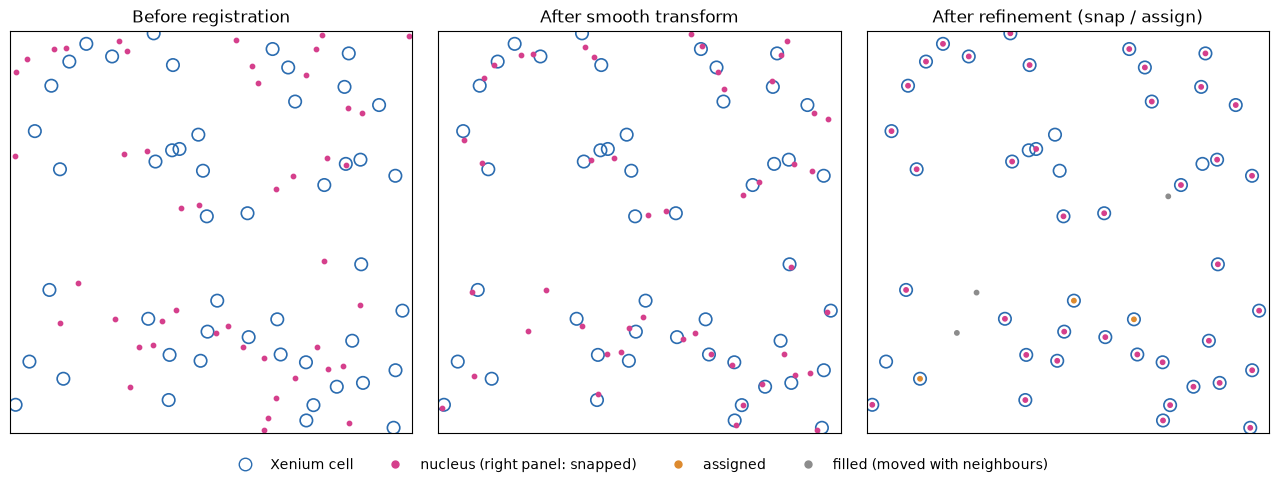

In [14]:
status = refined["status"]
colors = np.where(status == "snapped", NUC, np.where(status == "assigned", ASSIGNED, "0.55"))
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
panel(axes[0], cells_xy, nuclei_xy, "Before registration", (700, 700))
panel(axes[1], cells_xy, result["transform"](nuclei_xy), "After smooth transform", (700, 700))
panel(axes[2], cells_xy, refined["refined_xy"], "After refinement (snap / assign)", (700, 700), colors=colors)
plt.tight_layout(rect=(0, 0.06, 1, 1)); status_legend(fig, pairs=False); plt.show()

## 5. From files, in one call

`register_centroid_files` reads both CSVs, registers, refines and writes the
whole source table back with new columns. The `smint-alignment centroid`
command runs exactly this (see [Command line](../../reference/cli/)).

In [15]:
from smint.alignment import register_centroid_files

table, result = register_centroid_files(
    "data/sample2_nuclei_z5_crop.csv",            # source: centroid_x / centroid_y
    "data/sample2_xenium_z5_crop.csv",            # target: x_centroid / y_centroid
    output_path="nuclei_registered.csv",
)
table.head()

INFO smint.alignment.centroid_registration: Initial TRE (held-out points, mutual NN <= 100.0): 11.3629


INFO smint.alignment.centroid_registration: RANSAC affine: 9/9 inliers (100.0%) at residual_threshold=6.0


INFO smint.alignment.centroid_registration: Round 1 (affine, 500-unit blocks): 9 blocks, 100% consistent, median NN 11.52 -> 4.86


INFO smint.alignment.centroid_registration: RANSAC affine: 28/36 inliers (77.8%) at residual_threshold=3.0


INFO smint.alignment.centroid_registration: Round 2 (tps, 250-unit blocks): 36 blocks, 78% consistent, median NN 4.86 -> 4.97 -- not an improvement, stopping


INFO smint.alignment.centroid_registration: TRE after multiround -- fit: 4.6646 | held-out validation: 5.1646


INFO smint.alignment.centroid_registration: Refinement: 1960 snapped and 255 assigned (89.5% of targets placed), 283 filled from neighbours; median neighbourhood deviation snapped 4.6 / assigned 9.0; held-out field check: median 4.55, 56% within 5


WARNING smint.alignment.centroid_registration: Assigned pairs deviate from their neighbourhood by a median 9.0 (snapped: 4.6): many are probably nuclei without a target placed on a neighbour's. Filter on neighbour_deviation, or use assign_remaining=False.


INFO smint.alignment.centroid_registration: Saved transformed centroids to nuclei_registered.csv


,centroid_x,centroid_y,x_transformed_smooth,y_transformed_smooth,registration_status,target_index,neighbour_deviation,x_transformed,y_transformed
0,1097.182,1246.459,1117.097363,1250.184470,snapped,1780,1.846967,1116.729,1249.105
1,958.538,280.531,974.554302,281.459015,snapped,1156,4.085995,973.168,277.570
2,486.989,1197.144,509.537308,1202.745707,assigned,1155,8.385566,509.718,1210.495
3,556.728,1081.367,578.403461,1086.344302,snapped,843,1.834303,577.314,1086.688
4,871.348,113.199,886.985484,113.853882,snapped,632,5.547007,883.387,114.851


| Column | Meaning |
|---|---|
| `x_transformed`, `y_transformed` | Final position: on the partner cell for snapped / assigned nuclei, otherwise the filled position |
| `x_transformed_smooth`, `y_transformed_smooth` | Position after the smooth transform only |
| `registration_status` | `snapped`, `assigned`, `filled` or `unmoved` |
| `target_index` | Row of the partner cell in the target file, `-1` if none |
| `neighbour_deviation` | Disagreement with the snapped neighbourhood, in µm (NaN when not placed) |

The same run from a terminal:

```bash
smint-alignment centroid \
    --source data/sample2_nuclei_z5_crop.csv \
    --target data/sample2_xenium_z5_crop.csv \
    --output-dir z5_crop_registration
```

Add `--submit --watch` to run it as a SLURM job instead (see
[Running on HPC](../../hpc_deployment/)).

## Next steps

- [Choosing a registration method](../../concepts/registration_methods/) — when
  to use this path and when to use STalign.
- [Sequential-section registration](../03_sequential_registration/) — when the
  two modalities come from neighbouring sections.
- [Alignment guide](../../alignment/) — every option of `register_centroids` and
  `refine_by_assignment`.